In [ ]:
import itertools as it
import pathlib
import random
import warnings

import alifedata_phyloinformatics_convert as apc
from hstrat import _auxiliary_lib as hstrat_aux
import iplotx as ipx
import marimo as mo
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from phyloframe import legacy as pfl
import polars as pl
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

from pylib import focal_sites_from_masks, osf_fetch

warnings.filterwarnings("ignore", category=DeprecationWarning)

OSF_SLUG = "kwx2s"
NUM_SITES = 64
N_BOOT = 10_000
NUM_TREES_DRAWN = 4
SEED = 1

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/alifedata_phyloinformatics_convert/_impl/phytrack_Systematcs.py:7: UserWarning: ImportWarning: phylotrackpy.Systematics import failed; inserting a no-op mock for Systematics. This is likely because phylotrackpy is not installed.
  warnings.warn(


In [ ]:
mo.md(f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
""")

```Text
Last updated: 2026-10-15T12:49:10.427351+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 6.17.0-1022-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

iplotx                            : 1.8.0
marimo                            : 0.23.2
hstrat                            : 1.25.2
pandas                            : 2.2.3
numpy                             : 2.1.2
seaborn                           : 0.13.2
phyloframe                        : 0.10.1
polars                            : 1.36.1
teeplot                           : 1.4.2
matplotlib                        : 3.10.9
alifedata_phyloinformatics_convert: 0.19.3
scipy                             : 1.14.1

```

In [ ]:
mo.md(f"""
# MLS Strong Fossils: Mutation-defined Clade Screen

Applies the phylogeny-based multilevel selection (MLS) screen from *Extending a Phylogeny-based Method for Detecting Signatures of Multi-level Selection for Applications in Artificial Life* (ISAL 2025, <https://doi.org/10.1162/ISAL.a.916>; code at <https://github.com/mmore500/multilevel-selection-concept>) to wafer-scale evolution data.

Data were generated by [`wse-async-ga` `wsclust/2026-10-13-mls-strong-fossils`](https://github.com/mmore500/wse-async-ga/tree/refactor-client-deps/wsclust/2026-10-13-mls-strong-fossils) and are hosted at <https://osf.io/{OSF_SLUG}>.
That file is the hstrat-reconstructed phylogeny (`04-build-phylo` output) with per-tip trait columns `trait_num0` ... `trait_num63`.
Focal (MLS) sites are coded `2` and background (neutral) sites `1` when present.

The screen asks whether the focal site

1. gives rise to more mutation-defined clades (MDCs) than expected for a neutral site (mutation-frequency screen), and
2. gives rise to MDCs that are smaller and/or shorter-lived than comparator MDCs (clade-fitness screen).
""")

# MLS Strong Fossils: Mutation-defined Clade Screen

Applies the phylogeny-based multilevel selection (MLS) screen from *Extending a Phylogeny-based Method for Detecting Signatures of Multi-level Selection for Applications in Artificial Life* (ISAL 2025, <https://doi.org/10.1162/ISAL.a.916>; code at <https://github.com/mmore500/multilevel-selection-concept>) to wafer-scale evolution data.

Data were generated by [`wse-async-ga` `wsclust/2026-10-13-mls-strong-fossils`](https://github.com/mmore500/wse-async-ga/tree/refactor-client-deps/wsclust/2026-10-13-mls-strong-fossils) and are hosted at <https://osf.io/kwx2s>.
That file is the hstrat-reconstructed phylogeny (`04-build-phylo` output) with per-tip trait columns `trait_num0` ... `trait_num63`.
Focal (MLS) sites are coded `2` and background (neutral) sites `1` when present.

The screen asks whether the focal site

1. gives rise to more mutation-defined clades (MDCs) than expected for a neutral site (mutation-frequency screen), and
2. gives rise to MDCs that are smaller and/or shorter-lived than comparator MDCs (clade-fitness screen).

## Get Data

In [ ]:
data_path = osf_fetch(OSF_SLUG)

downloading https://osf.io/kwx2s/download -> /tmp/kwx2s
size: 123703712 bytes


In [ ]:
_lazy = pl.scan_parquet(data_path)
_schema = _lazy.collect_schema()
_config_cols = [
    name
    for name in _schema.names()
    if name.startswith(
        ("ASYNC_GA_", "CEREBRASLIB_", "flag_", "dstream_algo")
    )
    or name
    in (
        "genomeFlavor",
        "populationFlavor",
        "globalSeed",
        "nCol",
        "nRow",
        "nWav",
        "nTrait",
        "nCycle",
        "tilePopSize",
        "tournSize",
        "replicate",
        "dstream_S",
        "hstrat_differentia_bitwidth",
    )
]
config_df = (
    _lazy.filter(pl.col("genomeFlavor").is_not_null())
    .select(_config_cols)
    .unique()
    .collect()
)
assert len(config_df) == 1, "expected a single run configuration"
config = config_df.row(0, named=True)
config_df.transpose(include_header=True, column_names=["value"])

column,value
str,str
"""hstrat_differentia_bitwidth""","""1"""
"""dstream_S""","""128"""
"""genomeFlavor""","""genome_mls_2025_08_15"""
"""globalSeed""","""1"""
"""populationFlavor""","""population_tournamentgeneratio…"
…,…
"""CEREBRASLIB_TRAITLOGGER_DSTREA…","""steady_algo"""
"""CEREBRASLIB_HSTRAT_T_DILATION""","""1"""
"""CEREBRASLIB_HSTRAT_DSTREAM_ALG…","""hybrid_0_steady_1_tilted_2_alg…"


In [ ]:
focal_sites = focal_sites_from_masks(
    [config[f"flag_is_focal_mask_byte{B}"] for B in range(8)],
)
background_sites = [
    site for site in range(NUM_SITES) if site not in focal_sites
]
focal_sites

In [ ]:
phylo_raw = pd.read_parquet(
    data_path,
    columns=[
        "id",
        "ancestor_id",
        "origin_time",
        "focal_trait_count",
        "nonfocal_trait_count",
        *(f"trait_num{site}" for site in range(NUM_SITES)),
    ],
)
phylo_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2565885 entries, 0 to 2565884
Data columns (total 69 columns):
 #   Column                Dtype  
---  ------                -----  
 0   id                    uint64 
 1   ancestor_id           uint64 
 2   origin_time           int64  
 3   focal_trait_count     float64
 4   nonfocal_trait_count  float64
 5   trait_num0            float64
 6   trait_num1            float64
 7   trait_num2            float64
 8   trait_num3            float64
 9   trait_num4            float64
 10  trait_num5            float64
 11  trait_num6            float64
 12  trait_num7            float64
 13  trait_num8            float64
 14  trait_num9            float64
 15  trait_num10           float64
 16  trait_num11           float64
 17  trait_num12           float64
 18  trait_num13           float64
 19  trait_num14           float64
 20  trait_num15           float64
 21  trait_num16           float64
 22  trait_num17           float64
 23  trait_n

In [ ]:
_tips = phylo_raw[phylo_raw["focal_trait_count"].notna()]
for _site in range(NUM_SITES):
    _expected = {0, 2} if _site in focal_sites else {0, 1}
    assert set(_tips[f"trait_num{_site}"].unique()) <= _expected, _site

assert (
    (_tips[[f"trait_num{s}" for s in focal_sites]] != 0).sum(axis=1)
    == _tips["focal_trait_count"]
).all()
"ok"

'ok'

## Prep Data

Fossil sets were sampled at two timepoints.
Fossils from the first set have `origin_time == -1` (sampled before any lineage history accumulated) and carry no information about clade fates, so only tips with `origin_time >= 0` are retained.
Lineages without retained tips are pruned and unifurcations collapsed.

In [ ]:
_tips = phylo_raw[phylo_raw["focal_trait_count"].notna()]
_tips.groupby(
    pd.cut(_tips["origin_time"], [-2, -0.5, 600, 700, 750, 800, 900]),
    observed=True,
).agg(
    num_tips=("id", "size"),
    focal_frac=("focal_trait_count", "mean"),
    nonfocal_mean=("nonfocal_trait_count", "mean"),
)

,num_tips,focal_frac,nonfocal_mean
origin_time,,,
"(-2.0, -0.5]",883350,0.000000,0.000000
"(600.0, 700.0]",106,0.028302,0.066038
"(700.0, 750.0]",289410,0.059072,0.087758
"(750.0, 800.0]",534683,0.072045,0.091914
"(800.0, 900.0]",11,0.000000,0.545455


In [ ]:
phylo = (
    phylo_raw.assign(
        extant=phylo_raw["focal_trait_count"].notna()
        & (phylo_raw["origin_time"] >= 0),
    )
    .pipe(pfl.alifestd_to_working_format)
    .pipe(pfl.alifestd_prune_extinct_lineages_asexual, mutate=True)
    .pipe(pfl.alifestd_collapse_unifurcations, mutate=True)
    .pipe(pfl.alifestd_to_working_format, mutate=True)
    .pipe(pfl.alifestd_mark_leaves, mutate=True)
    .pipe(pfl.alifestd_mark_roots, mutate=True)
    .pipe(pfl.alifestd_mark_root_id, mutate=True)
    .pipe(pfl.alifestd_mark_num_leaves_asexual, mutate=True)
    .pipe(pfl.alifestd_mark_clade_duration_asexual, mutate=True)
    .reset_index(drop=True)
)
assert (phylo["is_leaf"] == phylo["extant"]).all()

In [ ]:
pd.Series(
    {
        "num_nodes": len(phylo),
        "num_leaves": int(phylo["is_leaf"].sum()),
        "num_roots": int(phylo["is_root"].sum()),
        "max_leaves_per_root": int(
            phylo.loc[phylo["is_root"], "num_leaves"].max()
        ),
        "median_leaves_per_root": float(
            phylo.loc[phylo["is_root"], "num_leaves"].median()
        ),
        "leaf_origin_time_min": phylo.loc[
            phylo["is_leaf"], "origin_time"
        ].min(),
        "leaf_origin_time_max": phylo.loc[
            phylo["is_leaf"], "origin_time"
        ].max(),
    },
).to_frame("value")

,value
num_nodes,1640115.0
num_leaves,824210.0
num_roots,8252.0
max_leaves_per_root,184.0
median_leaves_per_root,99.0
leaf_origin_time_min,669.0
leaf_origin_time_max,805.0


In [ ]:
mo.md(f"""
## Example Phylogenies

Radial tree drawings in the style of the reference work's wafer-scale figure.
The reconstructed phylogeny is a forest, so {NUM_TREES_DRAWN} trees with at least median tip count are sampled at random and drawn separately.
Diamonds mark tips carrying the MLS (focal) mutation; circles mark tips carrying any neutral (background) mutation.
""")

## Example Phylogenies

Radial tree drawings in the style of the reference work's wafer-scale figure.
The reconstructed phylogeny is a forest, so 4 trees with at least median tip count are sampled at random and drawn separately.
Diamonds mark tips carrying the MLS (focal) mutation; circles mark tips carrying any neutral (background) mutation.

teeplots/2026-10-15-mls-strong-fossils/edge-color=darkgray+layout=radial+root_id=428+viz=tree+ext=.pdf
teeplots/2026-10-15-mls-strong-fossils/edge-color=darkgray+layout=radial+root_id=428+viz=tree+ext=.png


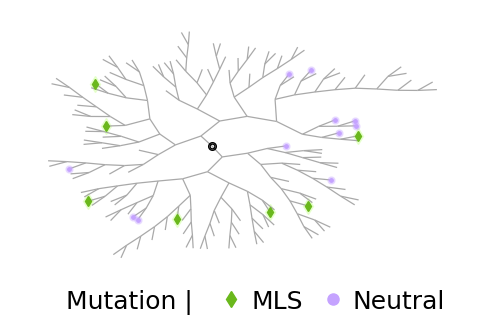

teeplots/2026-10-15-mls-strong-fossils/edge-color=darkgray+layout=radial+root_id=5032+viz=tree+ext=.pdf
teeplots/2026-10-15-mls-strong-fossils/edge-color=darkgray+layout=radial+root_id=5032+viz=tree+ext=.png


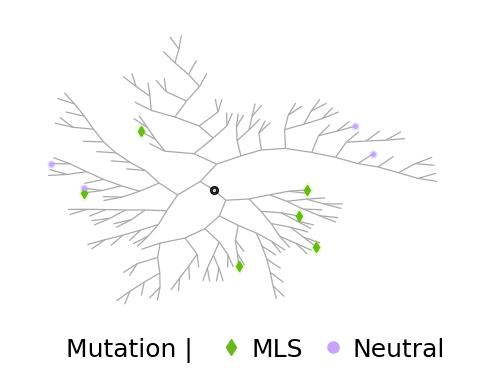

teeplots/2026-10-15-mls-strong-fossils/edge-color=darkgray+layout=radial+root_id=2778+viz=tree+ext=.pdf
teeplots/2026-10-15-mls-strong-fossils/edge-color=darkgray+layout=radial+root_id=2778+viz=tree+ext=.png


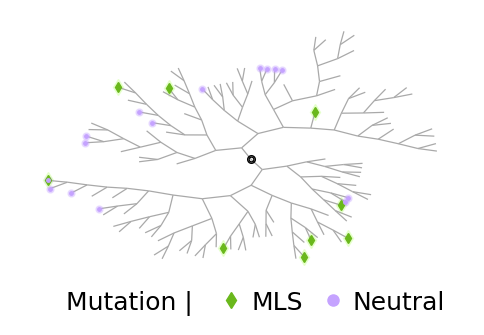

teeplots/2026-10-15-mls-strong-fossils/edge-color=darkgray+layout=radial+root_id=3923+viz=tree+ext=.pdf
teeplots/2026-10-15-mls-strong-fossils/edge-color=darkgray+layout=radial+root_id=3923+viz=tree+ext=.png


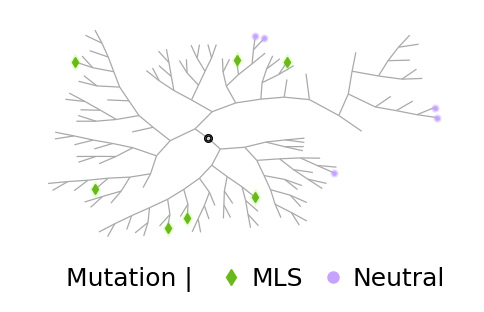

In [ ]:
_roots = phylo.loc[phylo["is_root"], ["id", "num_leaves"]]
_drawn_root_ids = (
    _roots[_roots["num_leaves"] >= _roots["num_leaves"].median()]
    .sample(n=NUM_TREES_DRAWN, random_state=SEED)
    .sort_values("num_leaves", ascending=False)["id"]
    .tolist()
)

for _root_id in _drawn_root_ids:
    _subtree = (
        phylo[phylo["root_id"] == _root_id]
        .pipe(pfl.alifestd_assign_contiguous_ids)
        .pipe(pfl.alifestd_try_add_ancestor_list_col)
    )
    _tree = apc.alife_dataframe_to_dendropy_tree(
        _subtree,
        setattrs=["focal_trait_count", "nonfocal_trait_count"],
    )
    with hstrat_aux.RngStateContext(6):
        _tree.ladderize()
        _tree.reorder(key=lambda *args: max(random.random(), 0.89))

    with tp.teed(
        ipx.plotting.tree,
        _tree,
        aspect=0.7,
        edge_color="darkgray",
        edge_linewidth=0.9,
        ladderize=True,
        layout="radial",
        layout_angular=True,
        layout_start=0.25,
        margins=0,
        teeplot_outattrs={"root_id": _root_id},
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _teed:
        plt.gcf().set_size_inches(6, 6)

        for _n, (_x, _y) in _teed.get_layout().T.items():
            _x_, _y_ = _x * np.cos(_y), _x * np.sin(_y)
            if _n.focal_trait_count == 1.0:
                plt.plot(
                    _x_,
                    _y_,
                    "d",
                    markersize=8,
                    color="#E2FFC4",
                    alpha=0.8,
                    zorder=0,
                )
                plt.plot(
                    _x_,
                    _y_,
                    "d",
                    markersize=5,
                    color="#6AB81C",
                    alpha=1,
                    zorder=2,
                )
            if _n.nonfocal_trait_count > 0:
                plt.plot(
                    _x_,
                    _y_,
                    "o",
                    markersize=5,
                    color="#C5A3FF",
                    alpha=0.3,
                    zorder=1,
                )
                plt.plot(
                    _x_,
                    _y_,
                    "o",
                    markersize=2.5,
                    color="#C5A3FF",
                    alpha=1.0,
                    zorder=3,
                )
            if _n is _tree.seed_node:
                for _size in 3.5, 5.5:
                    plt.plot(
                        _x_,
                        _y_,
                        "o",
                        markersize=_size,
                        color="black",
                        alpha=1,
                        fillstyle="none",
                    )

        plt.gca().margins(x=0.02, y=0.02)

        (_h0,) = plt.plot(
            [], [], "d", markersize=0, color="#FFFFFF", label="Mutation | "
        )
        (_h1,) = plt.plot(
            [], [], "d", markersize=8, color="#6AB81C", label="MLS"
        )
        (_h2,) = plt.plot(
            [], [], "o", markersize=8, color="#C5A3FF", label="Neutral"
        )
        plt.legend(
            handles=[_h0, _h1, _h2],
            loc="upper center",
            bbox_to_anchor=(0.48, 0.05),
            frameon=False,
            ncol=4,
            fontsize=18,
            columnspacing=0.2,
            handletextpad=-0.2,
        )
    plt.close("all")

## Screen Mutation-defined Clades

MDCs are identified for each of the 64 trait sites by Fitch maximum parsimony over tip states (root state assumed absent), as in the reference work's wafer-scale analysis.

In [ ]:
_work = phylo[["id", "ancestor_id"]].copy()
_is_leaf = phylo["is_leaf"].to_numpy()
mdc_masks = {}
for _site in mo.status.progress_bar(range(NUM_SITES)):
    _has = phylo[f"trait_num{_site}"].fillna(0).to_numpy() != 0
    mdc_masks[_site] = _work.pipe(
        pfl.alifestd_screen_trait_defined_clades_fitch_asexual,
        mutate=True,
        mask_trait_absent=_is_leaf & ~_has,
        mask_trait_present=_is_leaf & _has,
    ).astype(bool)

In [ ]:
mdcs = pd.concat(
    [
        phylo.loc[
            mask, ["id", "origin_time", "num_leaves", "clade_duration"]
        ].assign(site=site, is_focal=site in focal_sites)
        for site, mask in mdc_masks.items()
    ],
    ignore_index=True,
)
mdcs["mutation"] = np.where(mdcs["is_focal"], "MLS", "Neutral")
mdcs.groupby("mutation")[
    ["num_leaves", "clade_duration", "origin_time"]
].describe().T

mutation MLS Neutral num_leaves count 47996.000000 49051.000000 mean 4.836986 4.177489 std 8.076474 6.576883 min 1.000000 1.000000 25% 1.000000 1.000000 ... ... ... ... origin_time min 14.000000 14.000000 25% 78.000000 158.000000 50% 543.000000 535.000000 75% 753.000000 751.000000 max 799.000000 801.000000 24 rows × 2 columns

## Mutation-frequency Screen

Baseline rate $\lambda$ is the mean MDC count per background site.
Focal-site significance is the Poisson survival probability of observing at least the focal MDC count under $\mathsf{Pois}(\lambda)$.

In [ ]:
mdc_counts = (
    mdcs.groupby("site")
    .size()
    .reindex(range(NUM_SITES), fill_value=0)
    .rename("mdc_count")
    .to_frame()
)
mdc_counts["mutation"] = np.where(
    mdc_counts.index.isin(focal_sites), "MLS", "Neutral"
)
_lam = mdc_counts.loc[background_sites, "mdc_count"].mean()
freq_screen = pd.DataFrame(
    [
        {
            "site": site,
            "mdc_count": mdc_counts.loc[site, "mdc_count"],
            "lambda": _lam,
            "fold_enrichment": mdc_counts.loc[site, "mdc_count"] / _lam,
            "poisson_sf_p": scipy_stats.poisson.sf(
                mdc_counts.loc[site, "mdc_count"] - 1, _lam
            ),
            "background_rank": int(
                (
                    mdc_counts.loc[background_sites, "mdc_count"]
                    >= mdc_counts.loc[site, "mdc_count"]
                ).sum()
            ),
        }
        for site in focal_sites
    ],
)
freq_screen

,site,mdc_count,lambda,fold_enrichment,poisson_sf_p,background_rank
0,24,47996,778.587302,61.644982,0.0,0


teeplots/2026-10-15-mls-strong-fossils/hue=mutation+viz=barplot+x=site+y=mdc-count+ext=.pdf
teeplots/2026-10-15-mls-strong-fossils/hue=mutation+viz=barplot+x=site+y=mdc-count+ext=.png


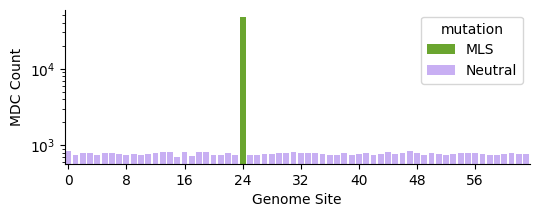

In [ ]:
with tp.teed(
    sns.barplot,
    data=mdc_counts.reset_index(),
    x="site",
    y="mdc_count",
    hue="mutation",
    hue_order=["MLS", "Neutral"],
    palette=["#6AB81C", "#C5A3FF"],
    dodge=False,
    teeplot_outexclude=["palette", "hue_order", "dodge"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    _ax.set_yscale("log")
    _ax.set_xlabel("Genome Site")
    _ax.set_ylabel("MDC Count")
    _ax.set_xticks(range(0, NUM_SITES, 8))
    sns.despine(ax=_ax)
    _ax.figure.set_size_inches(6, 2)

## Raw MDC Size

Following the reference wafer-scale MDC-size figure: leaf counts of MLS-site MDCs versus pooled neutral-site MDCs.
Raw sizes are confounded by MDC origin time; see normalized screen below.

teeplots/2026-10-15-mls-strong-fossils/hue=mutation+marker=o+viz=stripplot+x=mutation+y=num-leaves+ext=.pdf
teeplots/2026-10-15-mls-strong-fossils/hue=mutation+marker=o+viz=stripplot+x=mutation+y=num-leaves+ext=.png


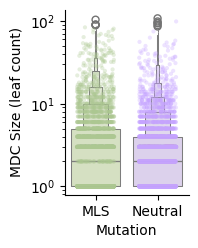

In [ ]:
_strip_args = dict(
    x="mutation",
    y="num_leaves",
    hue="mutation",
    order=["MLS", "Neutral"],
    hue_order=["MLS", "Neutral"],
    alpha=0.3,
    jitter=0.3,
    legend=False,
    marker="o",
    s=3,
)
_sample = (
    mdcs.groupby("mutation", group_keys=False)
    .apply(lambda g: g.sample(n=min(len(g), 3000), random_state=SEED))
    .reset_index(drop=True)
)
with tp.teed(
    sns.stripplot,
    data=_sample,
    **_strip_args,
    palette=["#ACC791", "#C5A3FF"],
    teeplot_outexclude=["palette", "hue_order", "order", "jitter", "s"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    sns.boxenplot(
        data=mdcs,
        x="mutation",
        y="num_leaves",
        hue="mutation",
        order=["MLS", "Neutral"],
        hue_order=["MLS", "Neutral"],
        palette=["#D6E5BD", "#DBCDF0"],
        legend=False,
        ax=_ax,
    )
    _ax.set_yscale("log")
    _ax.set_xlabel("Mutation")
    _ax.set_ylabel("MDC Size (leaf count)")
    sns.despine(ax=_ax)
    _ax.figure.set_size_inches(1.6, 2.4)

## Clade-fitness Screen

Each MDC's clade size (`num_leaves`) and clade duration are percentile-ranked (mean rank for ties) against comparator MDCs.
Comparators are the pooled MDCs of background (neutral) sites, i.e., MDCs for *other* mutations.
Under the `epochN` normalizations, comparison is restricted to comparators originating within the same `N`-update `origin_time` bin, controlling for recency bias.
Under the null, mean percentile is 50; MLS predicts mean percentile below 50.

In [ ]:
normalizations = {"all": None, "epoch100": 100, "epoch50": 50}
stat_cols = ("num_leaves", "clade_duration")
normed = mdcs.copy()
_comparator = ~normed["is_focal"].to_numpy()
for _norm, _binwidth in normalizations.items():
    _epoch = (
        np.zeros(len(normed), dtype=int)
        if _binwidth is None
        else (normed["origin_time"].to_numpy() // _binwidth).astype(int)
    )
    for _stat in stat_cols:
        _values = normed[_stat].to_numpy().astype(float)
        _result = np.full(len(normed), np.nan)
        _num_comparators = np.zeros(len(normed), dtype=int)
        for _e in np.unique(_epoch):
            _in_epoch = _epoch == _e
            _comps = _values[_in_epoch & _comparator]
            _num_comparators[_in_epoch] = len(_comps)
            if len(_comps):
                # score unique values only, as scipy broadcasts
                # values x comparators in memory
                _uniq, _inv = np.unique(
                    _values[_in_epoch], return_inverse=True
                )
                _result[_in_epoch] = scipy_stats.percentileofscore(
                    _comps, _uniq, kind="mean"
                )[_inv]
        normed[f"pct_{_norm}-{_stat}"] = _result
        normed[f"ncomp_{_norm}-{_stat}"] = _num_comparators

In [ ]:
_rng = np.random.default_rng(SEED)
_records = []
for _norm, _stat in it.product(normalizations, stat_cols):
    _col = f"pct_{_norm}-{_stat}"
    _focal = normed.loc[normed["is_focal"], _col].dropna().to_numpy()
    _background = normed.loc[~normed["is_focal"], _col].dropna()
    _site_means = (
        normed.loc[~normed["is_focal"]].groupby("site")[_col].mean()
    )
    _boot = scipy_stats.bootstrap(
        (_focal,),
        np.mean,
        n_resamples=N_BOOT,
        batch=max(1, 2**24 // len(_focal)),
        method="percentile",
        random_state=_rng,
    )
    _mw_u, _mw_p = scipy_stats.mannwhitneyu(
        _focal, _background.to_numpy(), alternative="less"
    )
    _records.append(
        {
            "normalization": _norm,
            "stat": _stat,
            "n_focal": len(_focal),
            "n_background": len(_background),
            "focal_mean_pct": _focal.mean(),
            "focal_mean_pct_ci_low": _boot.confidence_interval.low,
            "focal_mean_pct_ci_high": _boot.confidence_interval.high,
            "background_site_mean_pct_min": _site_means.min(),
            "background_site_mean_pct_max": _site_means.max(),
            "background_sites_below_focal": int(
                (_site_means < _focal.mean()).sum()
            ),
            # bootstrap p-value for mean percentile < 50
            "p_boot_mean_lt_50": np.mean(
                _boot.bootstrap_distribution >= 50.0
            ),
            "p_mw_less": _mw_p,
            "cliffs_delta": 2 * _mw_u / (len(_focal) * len(_background))
            - 1,
        },
    )
fitness_screen = pd.DataFrame(_records)
fitness_screen

,normalization,stat,n_focal,n_background,focal_mean_pct,focal_mean_pct_ci_low,focal_mean_pct_ci_high,background_site_mean_pct_min,background_site_mean_pct_max,background_sites_below_focal,p_boot_mean_lt_50,p_mw_less,cliffs_delta
0,all,num_leaves,47996,49051,48.941654,48.664988,49.211626,48.086949,51.763076,8,0.0000,1.122559e-09,-0.021167
1,all,clade_duration,47996,49051,50.074346,49.793757,50.358657,47.986737,51.727740,28,0.6967,6.622924e-01,0.001487
2,epoch100,num_leaves,47996,49051,50.343049,50.159247,50.522273,48.214611,51.324272,45,1.0000,1.000000e+00,0.028173
3,epoch100,clade_duration,47996,49051,50.646085,50.463736,50.834968,47.415009,51.763726,51,1.0000,9.999971e-01,0.016106
4,epoch50,num_leaves,47996,49051,49.963178,49.779849,50.137407,48.359772,51.369526,33,0.3391,1.000000e+00,0.027300
5,epoch50,clade_duration,47996,49051,49.942724,49.752182,50.128049,48.134945,51.752119,27,0.2660,8.879448e-01,0.004443


teeplots/2026-10-15-mls-strong-fossils/col=stat+hue=mutation+kind=strip+viz=catplot+x=normalization+y=percentile+ext=.pdf
teeplots/2026-10-15-mls-strong-fossils/col=stat+hue=mutation+kind=strip+viz=catplot+x=normalization+y=percentile+ext=.png


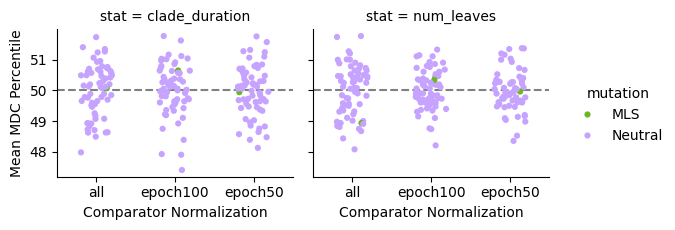

In [ ]:
_site_means = (
    normed.melt(
        id_vars=["site", "mutation"],
        value_vars=[c for c in normed.columns if c.startswith("pct_")],
        var_name="measure",
        value_name="percentile",
    )
    .groupby(["site", "mutation", "measure"], as_index=False)["percentile"]
    .mean()
)
_site_means[["normalization", "stat"]] = (
    _site_means["measure"].str.removeprefix("pct_").str.split("-").tolist()
)
with tp.teed(
    sns.catplot,
    data=_site_means,
    x="normalization",
    y="percentile",
    hue="mutation",
    col="stat",
    hue_order=["MLS", "Neutral"],
    palette=["#6AB81C", "#C5A3FF"],
    kind="strip",
    jitter=0.2,
    s=20,
    height=2.4,
    aspect=1.2,
    teeplot_outexclude=["palette", "hue_order", "jitter", "s"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    _g.refline(y=50, color="gray", linestyle="--")
    _g.set_axis_labels("Comparator Normalization", "Mean MDC Percentile")

teeplots/2026-10-15-mls-strong-fossils/col=stat+hue=mutation+kind=boxen+viz=catplot+x=normalization+y=percentile+ext=.pdf
teeplots/2026-10-15-mls-strong-fossils/col=stat+hue=mutation+kind=boxen+viz=catplot+x=normalization+y=percentile+ext=.png


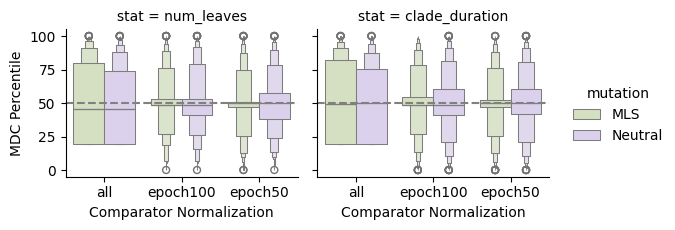

In [ ]:
_long = normed.melt(
    id_vars=["mutation"],
    value_vars=[c for c in normed.columns if c.startswith("pct_")],
    var_name="measure",
    value_name="percentile",
)
_long[["normalization", "stat"]] = (
    _long["measure"].str.removeprefix("pct_").str.split("-").tolist()
)
with tp.teed(
    sns.catplot,
    data=_long,
    x="normalization",
    y="percentile",
    hue="mutation",
    col="stat",
    hue_order=["MLS", "Neutral"],
    palette=["#D6E5BD", "#DBCDF0"],
    kind="boxen",
    height=2.4,
    aspect=1.2,
    teeplot_outexclude=["palette", "hue_order"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    _g.refline(y=50, color="gray", linestyle="--")
    _g.set_axis_labels("Comparator Normalization", "MDC Percentile")
plt.close("all")